# Лабораторна робота №8
## Самостійне моделювання на даних із зовнішніх джерел
**Студент:** Михайло Вахнюк. **Варіант:** 5.

**Мета:** отримати зовнішні табличні дані, обґрунтувати задачу, виконати підготовку без витоку інформації, порівняти чотири моделі, перевірити одну гіпотезу та зберегти процес прогнозування.

За датою запланованої угоди, віком будинку, відстанню до метро, кількістю магазинів і координатами прогнозуємо ціну одиниці площі житла в районі Сіньдянь, Новий Тайбей, на момент оцінювання перед угодою. Дата тут означає відомий період оцінювання, а справжня ціна ще невідома.

Це одновихідна регресія: різниця між цінами має числовий зміст. Ціль не округлюємо й не перетворюємо на класи. No — ідентифікатор, його виключаємо. Вихід Dense(1) без активації, loss=MSE; метрики MAE, RMSE, R². Критерій вибору — мінімум validation RMSE.

## 1. Підключення бібліотек

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import json, hashlib, platform, time, zipfile, urllib.request
from datetime import datetime
from pathlib import Path
import importlib.metadata as im
import joblib
import numpy as np
import pandas as pd
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display, Markdown

## 2. Seed, папки та версії середовища

In [1]:
SEED = 42
keras.utils.set_random_seed(SEED)
for folder in ["data", "artifacts", "figures"]:
    Path(folder).mkdir(parents=True, exist_ok=True)
versions = {name: im.version(name) for name in [
    "tensorflow", "numpy", "pandas", "matplotlib", "scikit-learn", "joblib", "openpyxl",
    "nbformat", "nbclient", "ipykernel"]}
print("Python:", platform.python_version())
display(pd.Series(versions, name="Версія"))

Python: 3.12.10


tensorflow      2.21.0
numpy            2.5.3
pandas           3.0.6
matplotlib      3.11.2
scikit-learn     1.9.1
joblib           1.6.0
openpyxl         3.1.5
nbformat        5.11.1
nbclient        0.11.0
ipykernel        7.3.0
Name: Версія, dtype: str

## 3. Отримання оригінального файла UCI

In [2]:
SOURCE_URL = "https://archive.ics.uci.edu/dataset/477/real+estate+valuation+data+set"
DOWNLOAD_URL = "https://archive.ics.uci.edu/static/public/477/real%2Bestate%2Bvaluation%2Bdata%2Bset.zip"
data_path = Path("data/Real estate valuation data set.xlsx")
passport_path = Path("data/source_passport.json")
if not data_path.exists():
    archive = Path("data/uci477.zip")
    urllib.request.urlretrieve(DOWNLOAD_URL, archive)
    with zipfile.ZipFile(archive) as z:
        members = [n for n in z.namelist() if n.endswith("Real estate valuation data set.xlsx")]
        assert len(members) == 1
        data_path.write_bytes(z.read(members[0]))
    downloaded_at = datetime.now().astimezone().isoformat()
else:
    downloaded_at = json.loads(passport_path.read_text(encoding="utf-8"))["downloaded_at"] if passport_path.exists() else datetime.now().astimezone().isoformat()

## 4. Читання Excel і визначення полів

In [2]:
book = pd.ExcelFile(data_path, engine="openpyxl")
sheet_name = book.sheet_names[0]
df = pd.read_excel(book, sheet_name=sheet_name)
TARGET = "Y house price of unit area"
DATE = "X1 transaction date"
FEATURES = ["X1 transaction date", "X2 house age", "X3 distance to the nearest MRT station",
            "X4 number of convenience stores", "X5 latitude", "X6 longitude"]
UNITS = "10 000 NTD / ping"

## 5. Паспорт джерела

In [2]:
passport = {
    "name": "Real Estate Valuation", "source_url": SOURCE_URL, "download_url": DOWNLOAD_URL,
    "creator": "I-Cheng Yeh, Department of Civil Engineering, Tamkang University",
    "citation": "Yeh, I. (2018). Real Estate Valuation. UCI Machine Learning Repository.",
    "doi": "10.24432/C5J30W", "license": "CC BY 4.0",
    "license_url": "https://creativecommons.org/licenses/by/4.0/",
    "downloaded_at": downloaded_at, "file": data_path.name, "sheet": sheet_name,
    "rows": len(df), "features": 6,
    "row_meaning": "Окремий історичний запис оцінювання/угоди житла, Сіньдянь, Новий Тайбей, Тайвань",
    "target": TARGET, "target_units": UNITS, "ping": "1 ping ≈ 3.3 м² за описом UCI",
    "sha256": hashlib.sha256(data_path.read_bytes()).hexdigest(),
}
passport_path.write_text(json.dumps(passport, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.Series(passport, name="Паспорт джерела"))

name                                         Real Estate Valuation
source_url       https://archive.ics.uci.edu/dataset/477/real+e...
download_url     https://archive.ics.uci.edu/static/public/477/...
creator          I-Cheng Yeh, Department of Civil Engineering, ...
citation         Yeh, I. (2018). Real Estate Valuation. UCI Mac...
doi                                                10.24432/C5J30W
license                                                  CC BY 4.0
license_url           https://creativecommons.org/licenses/by/4.0/
downloaded_at                     2026-11-10T11:54:03.599467+02:00
file                           Real estate valuation data set.xlsx
sheet                                                         工作表1
rows                                                           414
features                                                         6
row_meaning      Окремий історичний запис оцінювання/угоди житл...
target                                  Y house price of unit 

## 6. Перевірка розміру та схеми

In [2]:
assert len(df) == 414 and df.shape[1] == 8
assert df.columns.tolist() == ["No"] + FEATURES + [TARGET]
display(df.head())
print("Розмір:", df.shape)

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1


Розмір: (414, 8)


## 7. Типи, числові характеристики та пропуски

In [2]:
display(df.dtypes.to_frame("Тип"))
display(df.describe().T)
display(df.isna().sum().to_frame("Пропуски"))

,Тип
No,int64
X1 transaction date,float64
X2 house age,float64
X3 distance to the nearest MRT station,float64
X4 number of convenience stores,int64
X5 latitude,float64
X6 longitude,float64
Y house price of unit area,float64


,count,mean,std,min,25%,50%,75%,max
No,414.0,207.500000,119.655756,1.000000,104.250000,207.500000,310.750000,414.000000
X1 transaction date,414.0,2013.148953,0.281995,2012.666667,2012.916667,2013.166667,2013.416667,2013.583333
X2 house age,414.0,17.712560,11.392485,0.000000,9.025000,16.100000,28.150000,43.800000
X3 distance to the nearest MRT station,414.0,1083.885689,1262.109595,23.382840,289.324800,492.231300,1454.279000,6488.021000
X4 number of convenience stores,414.0,4.094203,2.945562,0.000000,1.000000,4.000000,6.000000,10.000000
X5 latitude,414.0,24.969030,0.012410,24.932070,24.963000,24.971100,24.977455,25.014590
X6 longitude,414.0,121.533361,0.015347,121.473530,121.528085,121.538630,121.543305,121.566270
Y house price of unit area,414.0,37.980193,13.606488,7.600000,27.700000,38.450000,46.600000,117.500000


,Пропуски
No,0
X1 transaction date,0
X2 house age,0
X3 distance to the nearest MRT station,0
X4 number of convenience stores,0
X5 latitude,0
X6 longitude,0
Y house price of unit area,0


## 8. Дублікати та рядки без цілі

In [2]:
print("Повні дублікати:", df.duplicated().sum())
print("Дублікати без No:", df.drop(columns="No").duplicated().sum())
assert df["No"].is_unique
assert all(pd.api.types.is_numeric_dtype(df[c]) for c in FEATURES + [TARGET])
print("Рядки без цілі:", df[TARGET].isna().sum())
clean = df.dropna(subset=[TARGET]).copy()
assert np.isfinite(clean[TARGET]).all()

Повні дублікати: 0
Дублікати без No: 0
Рядки без цілі: 0


Ціль — ціна одиниці площі в **10 000 NTD/ping**, де 1 ping ≈ 3.3 м² за UCI. Вік вимірюється роками, відстань до метро — метрами, координати — градусами. Рядки без цілі виключаємо. Ідентифікатор No до ознак не включаємо. Повтори без No не видаляємо автоматично: вони можуть бути окремими угодами; їх кількість та перетини перевіряємо явно.

## 9. Хронологічні межі без розриву однакових дат

In [3]:
# Межі шукаємо серед унікальних дат: жодну дату не розриваємо.
dates = np.sort(clean[DATE].unique())
counts = clean.groupby(DATE).size().reindex(dates).to_numpy()
cumulative = np.cumsum(counts)
candidates = [(abs(cumulative[i]/len(clean)-.70) + abs(cumulative[j]/len(clean)-.85), i, j)
              for i in range(len(dates)-2) for j in range(i+1, len(dates)-1)]
_, cut1, cut2 = min(candidates)
ordered = clean.sort_values([DATE, "No"], kind="stable")
train_df = ordered[ordered[DATE] <= dates[cut1]].copy()
val_df = ordered[(ordered[DATE] > dates[cut1]) & (ordered[DATE] <= dates[cut2])].copy()
test_df = ordered[ordered[DATE] > dates[cut2]].copy()
splits = {"train": train_df, "validation": val_df, "test": test_df}

## 10. Розміри та періоди вибірок

In [3]:
split_rows = []
for name, part in splits.items():
    split_rows.append({"split": name, "rows": len(part), "fraction": len(part)/len(clean),
                       "first_date": part[DATE].min(), "last_date": part[DATE].max()})
split_summary = pd.DataFrame(split_rows)
display(split_summary)
split_summary.to_csv("split_summary.csv", index=False)

,split,rows,fraction,first_date,last_date
0,train,286,0.690821,2012.666667,2013.333333
1,validation,58,0.140097,2013.416667,2013.416667
2,test,70,0.169082,2013.500000,2013.583333


## 11. Перевірка відсутності перетинів і збереження індексів

In [3]:
assert train_df[DATE].max() < val_df[DATE].min()
assert val_df[DATE].max() < test_df[DATE].min()
assert len(train_df) + len(val_df) + len(test_df) == len(clean)
for a, b in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    assert set(a.index).isdisjoint(b.index)
    assert set(a[DATE]).isdisjoint(b[DATE])
    assert set(map(tuple, a[FEATURES + [TARGET]].to_numpy())).isdisjoint(
        set(map(tuple, b[FEATURES + [TARGET]].to_numpy())))
split_indices = {name: part.index.tolist() for name, part in splits.items()}
Path("artifacts/split_indices.json").write_text(
    json.dumps(split_indices, indent=2), encoding="utf-8")

## 12. Відокремлення ознак і цілі

In [3]:
X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_val, y_val = val_df[FEATURES], val_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]

## 13. Розподіл цільової змінної на train

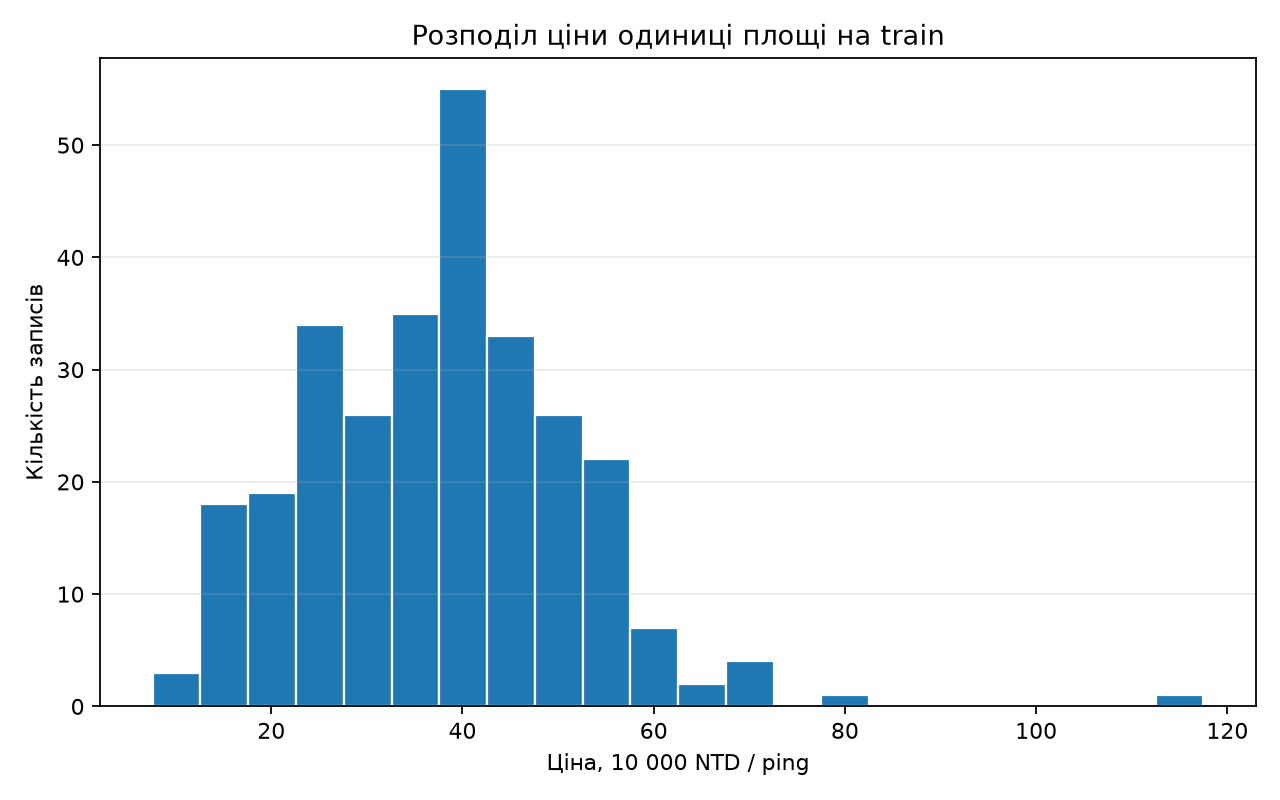

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(y_train, bins=22, edgecolor="white")
ax.set(title="Розподіл ціни одиниці площі на train", xlabel=f"Ціна, {UNITS}", ylabel="Кількість записів")
ax.grid(axis="y", alpha=.25)
fig.tight_layout(); fig.savefig("figures/train_target.png", dpi=160); plt.show()

## 14. Препроцесор: імпутація й масштабування

In [4]:
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), FEATURES)
])

## 15. Підготовка train, validation і test

In [4]:
train_ready = preprocessor.fit_transform(X_train).astype("float32")
val_ready = preprocessor.transform(X_val).astype("float32")
test_ready = preprocessor.transform(X_test).astype("float32")
for arr in [train_ready, val_ready, test_ready]:
    assert arr.shape[1] == len(FEATURES) and np.isfinite(arr).all()
print("Підготовлені форми:", train_ready.shape, val_ready.shape, test_ready.shape)
print("Порядок:", preprocessor.get_feature_names_out())

Підготовлені форми: (286, 6) (58, 6) (70, 6)
Порядок: ['numeric__X1 transaction date' 'numeric__X2 house age'
 'numeric__X3 distance to the nearest MRT station'
 'numeric__X4 number of convenience stores' 'numeric__X5 latitude'
 'numeric__X6 longitude']


## 16. Функція метрик регресії

In [4]:
def metrics(y, prediction):
    prediction = np.asarray(prediction).reshape(-1)
    assert len(prediction) == len(y) and np.isfinite(prediction).all()
    return {"MAE": float(mean_absolute_error(y, prediction)),
            "RMSE": float(np.sqrt(mean_squared_error(y, prediction))),
            "R2": float(r2_score(y, prediction))}

## 17. DummyRegressor і LinearRegression

In [4]:
dummy = DummyRegressor(strategy="mean").fit(train_ready, y_train)
linear = LinearRegression().fit(train_ready, y_train)
validation = {"Dummy": metrics(y_val, dummy.predict(val_ready)),
              "LinearRegression": metrics(y_val, linear.predict(val_ready))}
display(pd.DataFrame(validation).T)

,MAE,RMSE,R2
Dummy,9.406499,11.679791,-0.003843
LinearRegression,6.097237,7.592023,0.575859


## 18. Побудова нейромережі

In [5]:
def build_model(width=32, dropout=0.0):
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([layers.Input(shape=(train_ready.shape[1],))])
    for _ in range(2):
        model.add(layers.Dense(width, activation="relu"))
        if dropout:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=.001), loss="mse", metrics=["mae"])
    return model

## 19. Спільна функція навчання та callbacks

In [5]:
def train_model(model, name):
    checkpoint = Path("artifacts") / f"{name}_best.keras"
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
                 keras.callbacks.ModelCheckpoint(str(checkpoint), monitor="val_loss", save_best_only=True)]
    started = time.perf_counter()
    history = model.fit(train_ready, y_train.to_numpy(dtype="float32").reshape(-1, 1),
        validation_data=(val_ready, y_val.to_numpy(dtype="float32").reshape(-1, 1)),
        epochs=200, batch_size=64, callbacks=callbacks, verbose=2)
    elapsed = time.perf_counter() - started
    pd.DataFrame(history.history).rename_axis("epoch_zero_based").to_csv(f"{name}_history.csv")
    info = {"epochs": len(history.history["loss"]),
            "best_epoch": int(np.argmin(history.history["val_loss"]) + 1), "seconds": elapsed}
    return keras.models.load_model(checkpoint), history, info

## 20. Базова мережа: архітектура та навчання

In [5]:
base = build_model()
base.summary()
base, history_base, info_base = train_model(base, "NN_base")
validation["NN_base"] = metrics(y_val, base.predict(val_ready, verbose=0))
print("Базова мережа:", info_base, validation["NN_base"])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313 (5.13 KB)

 Trainable params: 1,313 (5.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200


... (106 outputs left out)

5/5 - 0s - 28ms/step - loss: 91.5464 - mae: 6.8165 - val_loss: 114.9008 - val_mae: 8.9985


Epoch 55/200


5/5 - 0s - 22ms/step - loss: 90.1613 - mae: 6.7560 - val_loss: 115.2247 - val_mae: 9.0216


Базова мережа: {'epochs': 55, 'best_epoch': 40, 'seconds': 10.491540899965912} {'MAE': 6.430446762874209, 'RMSE': 7.756661616788446, 'R2': 0.5572634004126635}


## 21. Гіпотеза однієї зміни до перегляду test

In [6]:
# Гіпотезу фіксуємо до нового fit та будь-якого тестового прогнозу.
best_i = info_base["best_epoch"] - 1
train_mse = float(history_base.history["loss"][best_i])
val_mse = float(history_base.history["val_loss"][best_i])
if val_mse > 1.5 * train_mse:
    improved_kwargs = {"width": 32, "dropout": .1}
    change = "Dropout(0.1) після кожного прихованого шару; ширина 32 без змін"
    hypothesis = (f"На найкращій епосі train MSE={train_mse:.3f}, validation MSE={val_mse:.3f}. "
                  "Великий розрив може означати перенавчання (або часовий зсув). "
                  "Перевіряємо лише додавання Dropout(0.1): очікуємо зменшення validation RMSE.")
else:
    improved_kwargs = {"width": 64, "dropout": 0.0}
    change = "Ширина прихованих шарів 32 → 64; learning rate та решта налаштувань без змін"
    hypothesis = (f"На найкращій епосі train MSE={train_mse:.3f}, validation MSE={val_mse:.3f}; "
                  "validation MSE не перевищує train MSE у 1.5 раза, явного великого розриву немає. "
                  "Перевіряємо збільшення лише ширини 32 → 64 для точнішої нелінійної залежності; "
                  "очікуємо зменшення validation RMSE. Це гіпотеза, а не доказ недостатньої місткості.")
Path("artifacts/hypothesis.json").write_text(json.dumps({"hypothesis": hypothesis, "change": change,
    "train_mse_at_best": train_mse, "val_mse_at_best": val_mse, "kwargs": improved_kwargs},
    ensure_ascii=False, indent=2), encoding="utf-8")
display(Markdown("**Гіпотеза до експерименту:** " + hypothesis))

**Гіпотеза до експерименту:** На найкращій епосі train MSE=171.965, validation MSE=60.166; validation MSE не перевищує train MSE у 1.5 раза, явного великого розриву немає. Перевіряємо збільшення лише ширини 32 → 64 для точнішої нелінійної залежності; очікуємо зменшення validation RMSE. Це гіпотеза, а не доказ недостатньої місткості.

## 22. Створення та навчання зміненої мережі

In [6]:
improved = build_model(**improved_kwargs)
improved.summary()
improved, history_improved, info_improved = train_model(improved, "NN_improved")
validation["NN_improved"] = metrics(y_val, improved.predict(val_ready, verbose=0))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,673 (18.25 KB)

 Trainable params: 4,673 (18.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200


... (76 outputs left out)

5/5 - 0s - 25ms/step - loss: 78.9955 - mae: 6.4736 - val_loss: 124.4282 - val_mae: 9.3868


Epoch 40/200


5/5 - 0s - 28ms/step - loss: 77.8842 - mae: 6.4150 - val_loss: 124.6074 - val_mae: 9.4004


C:\Users\Михайло\AppData\Local\Temp\ipykernel_9872\1209667703.py:36: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); fig.savefig("figures/training_loss.png", dpi=160); plt.show()


## 23. Криві train і validation loss

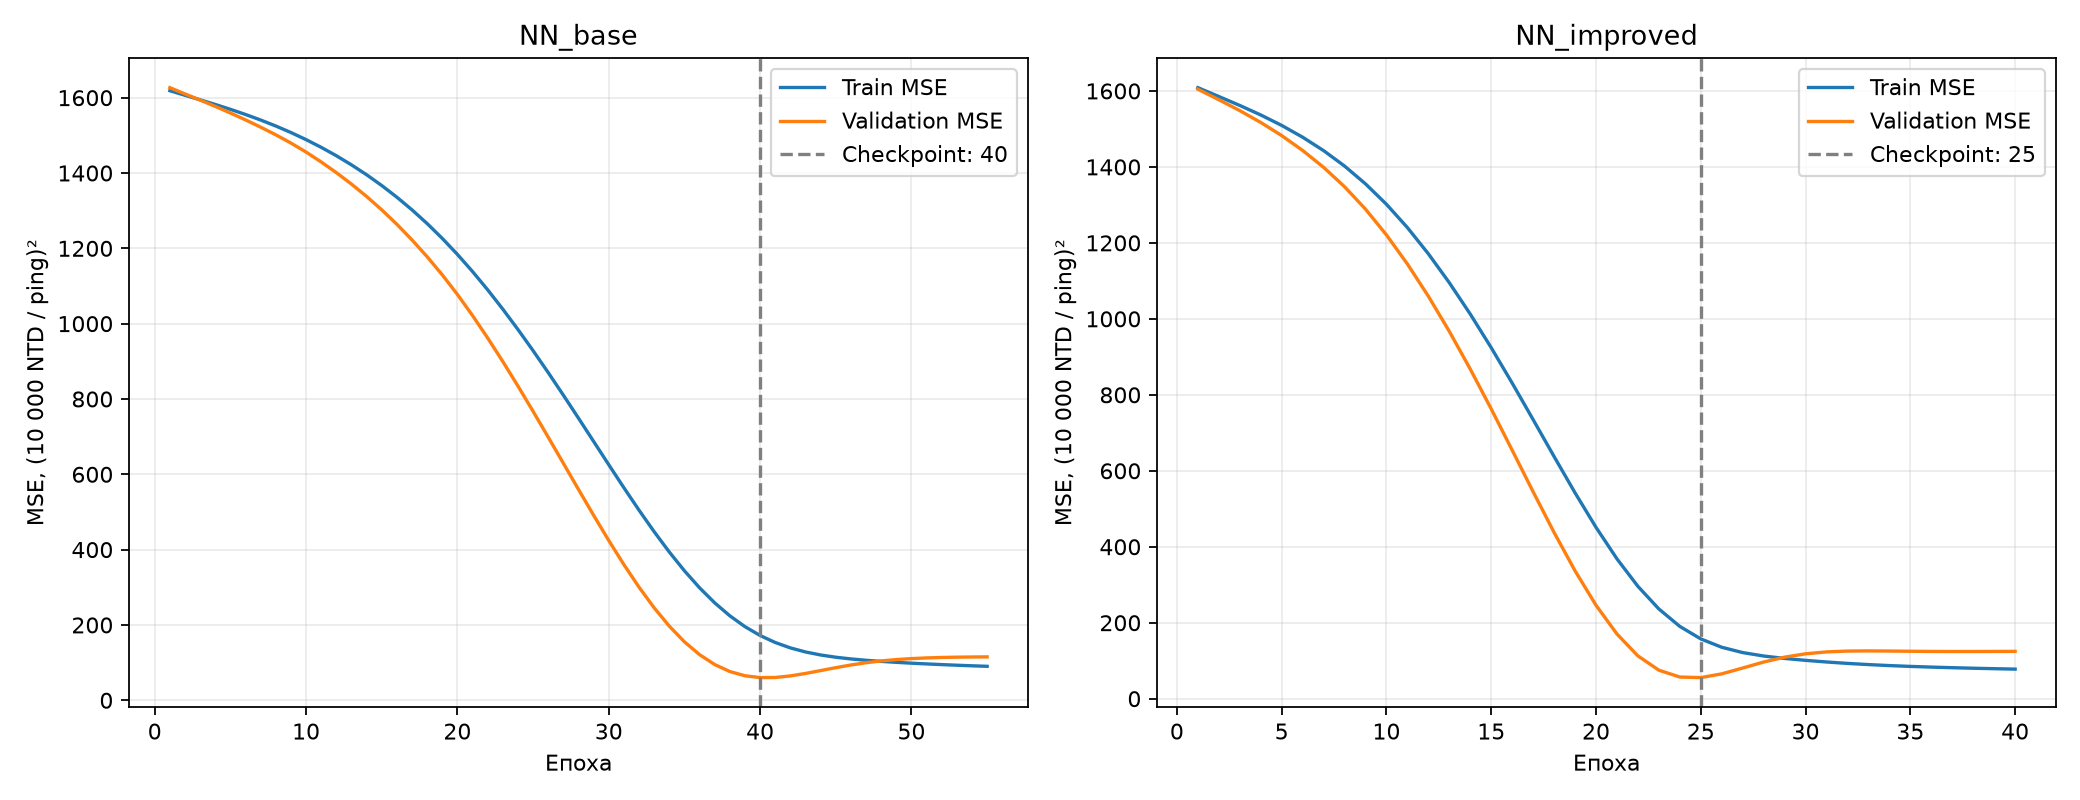

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, title, h, info in [(axes[0], "NN_base", history_base, info_base),
                           (axes[1], "NN_improved", history_improved, info_improved)]:
    e = np.arange(1, info["epochs"]+1)
    ax.plot(e, h.history["loss"], label="Train MSE")
    ax.plot(e, h.history["val_loss"], label="Validation MSE")
    ax.axvline(info["best_epoch"], color="gray", linestyle="--", label=f"Checkpoint: {info['best_epoch']}")
    ax.set(title=title, xlabel="Епоха", ylabel=f"MSE, ({UNITS})²")
    ax.legend(); ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig("figures/training_loss.png", dpi=160); plt.show()

## 24. Validation-порівняння та фіксація вибору до test

In [6]:
validation_table = pd.DataFrame(validation).T.rename_axis("model")
validation_table.to_csv("validation_results.csv")
selected_nn_name = "NN_improved" if validation["NN_improved"]["RMSE"] < validation["NN_base"]["RMSE"] else "NN_base"
best_overall_name = min(validation, key=lambda name: validation[name]["RMSE"])
models = {"Dummy": dummy, "LinearRegression": linear, "NN_base": base, "NN_improved": improved}
selected_model = models[selected_nn_name]
decision = {"criterion": "minimum validation RMSE", "selected_nn": selected_nn_name,
            "best_overall": best_overall_name, "validation_metrics": validation,
            "change": change, "test_used_for_selection": False}
Path("artifacts/selection_before_test.json").write_text(json.dumps(decision, ensure_ascii=False, indent=2), encoding="utf-8")
display(validation_table)
print("Краща нейромережа:", selected_nn_name, "; краща загалом:", best_overall_name)
print("Гіпотеза:", "покращила RMSE" if selected_nn_name == "NN_improved" else "не покращила RMSE")

,MAE,RMSE,R2
model,,,
Dummy,9.406499,11.679791,-0.003843
LinearRegression,6.097237,7.592023,0.575859
NN_base,6.430447,7.756662,0.557263
NN_improved,6.083480,7.451385,0.591427


Краща нейромережа: NN_improved ; краща загалом: NN_improved
Гіпотеза: покращила RMSE


## 25. Фінальне test-оцінювання чотирьох моделей

In [7]:
test_predictions = {}
comparison_rows = []
for name, model in models.items():
    prediction = model.predict(test_ready, verbose=0).reshape(-1) if name.startswith("NN_") else model.predict(test_ready)
    test_predictions[name] = prediction
    info = info_base if name == "NN_base" else info_improved if name == "NN_improved" else {}
    comparison_rows.append({"model": name,
        **{f"validation_{k}": v for k, v in validation[name].items()},
        **{f"test_{k}": v for k, v in metrics(y_test, prediction).items()},
        "change": change if name == "NN_improved" else "Базова конфігурація",
        "epochs": info.get("epochs"), "best_epoch": info.get("best_epoch"),
        "training_seconds": info.get("seconds"),
        "selected_nn": name == selected_nn_name, "best_overall": name == best_overall_name})
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv("model_comparison.csv", index=False)
display(comparison)

,model,validation_MAE,validation_RMSE,validation_R2,test_MAE,test_RMSE,test_R2,change,epochs,best_epoch,training_seconds,selected_nn,best_overall
0,Dummy,9.406499,11.679791,-0.003843,12.057692,14.404468,-0.003715,Базова конфігурація,NaN,NaN,NaN,False,False
1,LinearRegression,6.097237,7.592023,0.575859,7.510653,9.493551,0.564013,Базова конфігурація,NaN,NaN,NaN,False,False
2,NN_base,6.430447,7.756662,0.557263,7.358754,9.347977,0.577281,Базова конфігурація,55.0,40.0,10.491541,False,False
3,NN_improved,6.083480,7.451385,0.591427,8.160947,10.595183,0.456959,Ширина прихованих шарів 32 → 64; learning rate...,40.0,25.0,7.007625,True,True


## 26. Таблиця прогнозів і п’ять найбільших помилок

In [7]:
predictions_table = test_df[["No"] + FEATURES + [TARGET]].copy()
predictions_table.insert(0, "source_index", test_df.index)
for name, prediction in test_predictions.items():
    predictions_table[f"prediction_{name}"] = prediction
selected_prediction = test_predictions[selected_nn_name]
residual = y_test.to_numpy() - selected_prediction
predictions_table["selected_prediction"] = selected_prediction
predictions_table["residual"] = residual
predictions_table["absolute_error"] = np.abs(residual)
predictions_table.to_csv("test_predictions.csv", index=False)
largest_errors = predictions_table.nlargest(5, "absolute_error")
largest_errors.to_csv("largest_errors.csv", index=False)
display(largest_errors)

,source_index,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area,prediction_Dummy,prediction_LinearRegression,prediction_NN_base,prediction_NN_improved,selected_prediction,residual,absolute_error
35,35,36,2013.500000,13.9,4079.41800,0,25.01459,121.51816,27.3,37.730769,35.031769,42.374924,53.408092,53.408092,-26.108092,26.108092
148,148,149,2013.500000,16.4,3780.59000,0,24.93293,121.51203,45.1,37.730769,14.540422,18.333447,20.210281,20.210281,24.889719,24.889719
312,312,313,2013.583333,35.4,318.52920,9,24.97071,121.54069,78.0,37.730769,44.838135,50.832943,53.343697,53.343697,24.656303,24.656303
326,326,327,2013.500000,4.1,56.47425,7,24.95744,121.53711,62.1,37.730769,49.170025,45.646229,38.636803,38.636803,23.463197,23.463197
347,347,348,2013.583333,17.4,6488.02100,1,24.95719,121.47353,11.2,37.730769,10.366213,27.416000,32.795353,32.795353,-21.595353,21.595353


## 27. Графік фактичних і прогнозованих цін

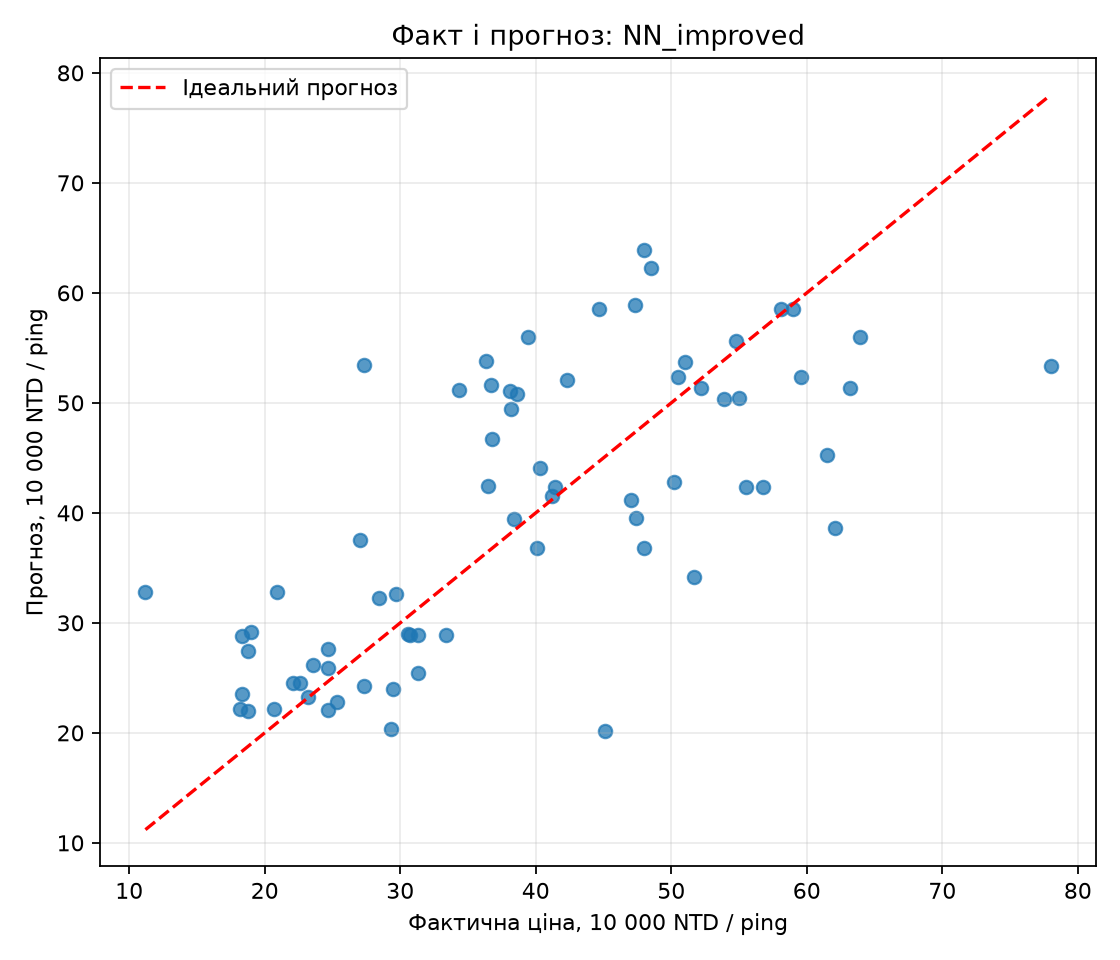

In [7]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, selected_prediction, alpha=.75)
low = min(y_test.min(), selected_prediction.min()); high = max(y_test.max(), selected_prediction.max())
ax.plot([low, high], [low, high], "r--", label="Ідеальний прогноз")
ax.set(title=f"Факт і прогноз: {selected_nn_name}", xlabel=f"Фактична ціна, {UNITS}", ylabel=f"Прогноз, {UNITS}")
ax.legend(); ax.grid(alpha=.25); fig.tight_layout()
fig.savefig("figures/actual_vs_predicted.png", dpi=160); plt.show()

## 28. Графік залишків

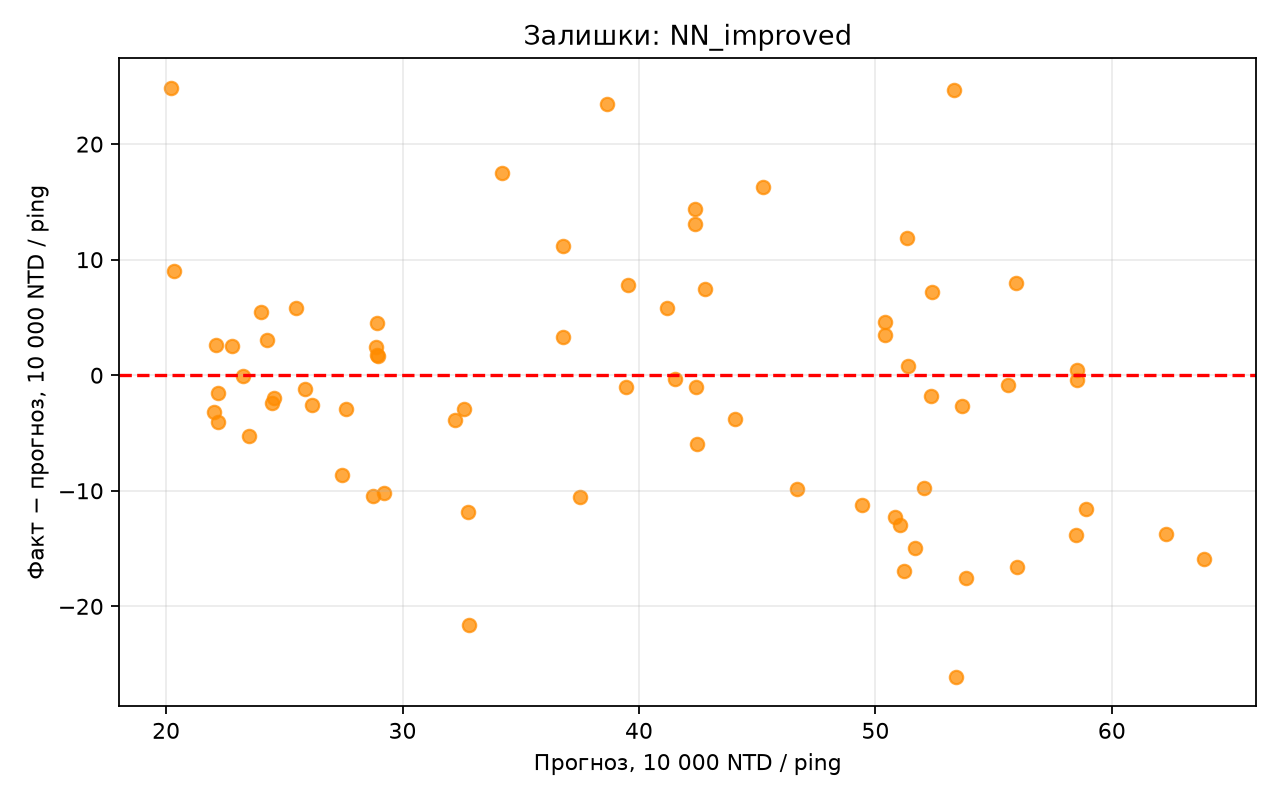

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(selected_prediction, residual, alpha=.75, color="darkorange")
ax.axhline(0, color="red", linestyle="--")
ax.set(title=f"Залишки: {selected_nn_name}", xlabel=f"Прогноз, {UNITS}", ylabel=f"Факт − прогноз, {UNITS}")
ax.grid(alpha=.25); fig.tight_layout(); fig.savefig("figures/residuals.png", dpi=160); plt.show()

## 29. Розбір конкретних найбільших помилок

In [7]:
for _, row in largest_errors.iterrows():
    direction = "занизила" if row["residual"] > 0 else "завищила"
    display(Markdown(f"- **No={int(row['No'])}:** дата {row[DATE]:.3f}, вік {row['X2 house age']:.1f} років, "
        f"до метро {row['X3 distance to the nearest MRT station']:.1f} м, магазинів {int(row['X4 number of convenience stores'])}; "
        f"факт {row[TARGET]:.2f}, прогноз {row['selected_prediction']:.2f}, "
        f"абсолютна помилка {row['absolute_error']:.2f} {UNITS}; модель {direction} оцінку. "
        "Можливі невраховані властивості житла (площа, стан, поверх) у таблиці відсутні; це пояснювальна гіпотеза, не встановлена причина."))

- **No=36:** дата 2013.500, вік 13.9 років, до метро 4079.4 м, магазинів 0; факт 27.30, прогноз 53.41, абсолютна помилка 26.11 10 000 NTD / ping; модель завищила оцінку. Можливі невраховані властивості житла (площа, стан, поверх) у таблиці відсутні; це пояснювальна гіпотеза, не встановлена причина.

- **No=149:** дата 2013.500, вік 16.4 років, до метро 3780.6 м, магазинів 0; факт 45.10, прогноз 20.21, абсолютна помилка 24.89 10 000 NTD / ping; модель занизила оцінку. Можливі невраховані властивості житла (площа, стан, поверх) у таблиці відсутні; це пояснювальна гіпотеза, не встановлена причина.

- **No=313:** дата 2013.583, вік 35.4 років, до метро 318.5 м, магазинів 9; факт 78.00, прогноз 53.34, абсолютна помилка 24.66 10 000 NTD / ping; модель занизила оцінку. Можливі невраховані властивості житла (площа, стан, поверх) у таблиці відсутні; це пояснювальна гіпотеза, не встановлена причина.

- **No=327:** дата 2013.500, вік 4.1 років, до метро 56.5 м, магазинів 7; факт 62.10, прогноз 38.64, абсолютна помилка 23.46 10 000 NTD / ping; модель занизила оцінку. Можливі невраховані властивості житла (площа, стан, поверх) у таблиці відсутні; це пояснювальна гіпотеза, не встановлена причина.

- **No=348:** дата 2013.583, вік 17.4 років, до метро 6488.0 м, магазинів 1; факт 11.20, прогноз 32.80, абсолютна помилка 21.60 10 000 NTD / ping; модель завищила оцінку. Можливі невраховані властивості житла (площа, стан, поверх) у таблиці відсутні; це пояснювальна гіпотеза, не встановлена причина.

## 30. Збереження обраної мережі та препроцесора

In [8]:
selected_model.save("artifacts/lab8_model.keras")
joblib.dump(preprocessor, "artifacts/preprocessor.joblib")
if not best_overall_name.startswith("NN_"):
    joblib.dump(models[best_overall_name], "artifacts/best_classical.joblib")

## 31. Збереження метаданих

In [8]:
metadata = {"source": passport, "target": TARGET, "target_units": UNITS,
    "task": "single-output regression", "features": FEATURES,
    "feature_units": ["decimal year", "year", "m", "count", "degree", "degree"],
    "prepared_feature_names": preprocessor.get_feature_names_out().tolist(),
    "classes": None, "positive_class": None, "seed": SEED,
    "split": "chronological, equal dates stay together", "indices": split_indices,
    "selected_nn": selected_nn_name, "best_overall": best_overall_name,
    "change": change, "hypothesis": hypothesis, "selection": decision,
    "versions": versions, "python": platform.python_version(),
    "input_dtype": "raw numeric DataFrame; prepared float32", "preprocessing_in_model": False}
Path("artifacts/metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
Path("metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")

## 32. Відновлення та порівняння прогнозів на трьох сирих рядках

In [8]:
probe_raw = X_val.iloc[:3].copy()
probe_raw.to_csv("artifacts/reload_probe.csv", index=False)
before = selected_model.predict(preprocessor.transform(probe_raw).astype("float32"), verbose=0)
np.save("artifacts/reload_expected.npy", before)
restored_preprocessor = joblib.load("artifacts/preprocessor.joblib")
restored_model = keras.models.load_model("artifacts/lab8_model.keras")
after = restored_model.predict(restored_preprocessor.transform(probe_raw).astype("float32"), verbose=0)
np.testing.assert_allclose(before, after, rtol=1e-5, atol=1e-6)
print("Перевірку відновлення всього комплекту пройдено.")
if not best_overall_name.startswith("NN_"):
    restored_classical = joblib.load("artifacts/best_classical.joblib")
    np.testing.assert_allclose(models[best_overall_name].predict(preprocessor.transform(probe_raw)),
        restored_classical.predict(restored_preprocessor.transform(probe_raw)), rtol=1e-5, atol=1e-6)
    print("Класичну модель також відновлено.")

Перевірку відновлення всього комплекту пройдено.


## 33. Версії залежностей у requirements.txt

In [8]:
Path("requirements.txt").write_text("".join(f"{k}=={v}\n" for k, v in versions.items()), encoding="utf-8")

166

## Інтерпретація отриманих графіків і меж оцінювання

**Гістограма.** більшість train-цін лежить приблизно між 20 і 60 (10 000 NTD/ping); є один дорогий запис понад 110. Його не видаляли. MSE сильно реагує на такі великі відхилення, тому менший validation loss порівняно з train не є помилкою: часові вибірки відрізняються за складом і складністю.

**Криві навчання.** базова мережа навчалася 55 епох, найкращий checkpoint — 40-та. Ширша — 40 епох, checkpoint — 25-та. Після мінімуму validation MSE зростає, поки train MSE зменшується; це ознака перенавчання/невідповідності часових розподілів і причина відновлювати checkpoint. Ширша мережа досягла меншого validation RMSE за меншу кількість епох.

**Факт і прогноз.** загальна додатна залежність відтворена, але розкид значний: частина дешевших об'єктів переоцінена, а деякі дорогі суттєво недооцінені. Лінія y=x є ідеальним прогнозом; окремі великі відстані від неї узгоджуються зі значенням RMSE.

**Залишки.** є як додатні, так і від'ємні залишки, величиною понад 20 одиниць; для прогнозів близько 50–65 видно кілька значних від'ємних залишків. Тому стверджувати відсутність систематичних недоліків не можна; діагностика показує слабкість окремих оцінок, а не придатність до реального оцінювання житла.

**Важливий результат:** покращення на validation не перенеслося на test: RMSE NN_improved=10.595, NN_base=9.348, LinearRegression=9.494, Dummy=14.404. Обрану раніше NN_improved збережено, додаткових налаштувань після test не було. Validation містить лише одну дату з 58 записами; така оцінка чутлива до особливостей періоду. Перемога за validation не гарантує перемоги на майбутніх даних.


## 34. Висновок за фактичними результатами

In [9]:
selected_row = comparison.set_index("model").loc[selected_nn_name]
delta = validation["NN_improved"]["RMSE"] - validation["NN_base"]["RMSE"]
nn_better_dummy = selected_row["test_RMSE"] < comparison.set_index("model").loc["Dummy", "test_RMSE"]
nn_better_linear = selected_row["test_RMSE"] < comparison.set_index("model").loc["LinearRegression", "test_RMSE"]
conclusion = (
    "Розв'язано задачу регресії ціни одиниці площі житла Real Estate Valuation за шістьма ознаками з часовим поділом без розриву дат. "
    f"Джерело має {len(df)} рядків, пропусків у таблиці {int(df.isna().sum().sum())}, повторів без No {int(df.drop(columns='No').duplicated().sum())}; ідентифікатор No виключено, цілі не підмінювали. "
    f"За validation RMSE краща модель загалом — {best_overall_name}, краща нейромережа — {selected_nn_name} "
    f"із RMSE {validation[selected_nn_name]['RMSE']:.3f} {UNITS}. "
    f"Перевірено одну зміну: {change}; різниця validation RMSE (improved − base) становить {delta:+.3f}, "
    + ("тому гіпотеза покращення підтвердилася в цьому поділі. " if delta < 0 else "тому гіпотеза покращення в цьому поділі не підтвердилася. ")
    + f"На test обрана мережа отримала MAE={selected_row['test_MAE']:.3f}, RMSE={selected_row['test_RMSE']:.3f} {UNITS}, R²={selected_row['test_R2']:.3f}; "
    + ("перевершила" if nn_better_dummy else "не перевершила") + " Dummy та "
    + ("перевершила" if nn_better_linear else "не перевершила") + " LinearRegression за test RMSE, але рішення про вибір за test не змінювали. "
    + f"Максимальна абсолютна test-помилка становить {np.max(np.abs(residual)):.3f} {UNITS}; розбір п'яти найбільших помилок і графік залишків показують обмеження індивідуальних прогнозів. "
    + "Відновлення моделі разом із препроцесором перевірено збігом прогнозів на трьох сирих рядках. "
    + "Набір невеликий, історичний, локальний і не містить важливих характеристик житла, тому отримані метрики не гарантують якості в інших містах або сучасних умовах."
)
display(Markdown("## Висновок\n\n" + conclusion))
Path("conclusion.txt").write_text(conclusion, encoding="utf-8")

## Висновок

Розв'язано задачу регресії ціни одиниці площі житла Real Estate Valuation за шістьма ознаками з часовим поділом без розриву дат. Джерело має 414 рядків, пропусків у таблиці 0, повторів без No 0; ідентифікатор No виключено, цілі не підмінювали. За validation RMSE краща модель загалом — NN_improved, краща нейромережа — NN_improved із RMSE 7.451 10 000 NTD / ping. Перевірено одну зміну: Ширина прихованих шарів 32 → 64; learning rate та решта налаштувань без змін; різниця validation RMSE (improved − base) становить -0.305, тому гіпотеза покращення підтвердилася в цьому поділі. На test обрана мережа отримала MAE=8.161, RMSE=10.595 10 000 NTD / ping, R²=0.457; перевершила Dummy та не перевершила LinearRegression за test RMSE, але рішення про вибір за test не змінювали. Максимальна абсолютна test-помилка становить 26.108 10 000 NTD / ping; розбір п'яти найбільших помилок і графік залишків показують обмеження індивідуальних прогнозів. Відновлення моделі разом із препроцесором перевірено збігом прогнозів на трьох сирих рядках. Набір невеликий, історичний, локальний і не містить важливих характеристик житла, тому отримані метрики не гарантують якості в інших містах або сучасних умовах.

## 35. Оформлення README

In [9]:
readme = f"""# Лабораторна робота №8 — варіант 5
Студент: Михайло Вахнюк.

## Джерело та отримання
Real Estate Valuation, I-Cheng Yeh (2018), Tamkang University; UCI, DOI 10.24432/C5J30W.
{SOURCE_URL}
Ліцензія CC BY 4.0: https://creativecommons.org/licenses/by/4.0/
Архів: {DOWNLOAD_URL}
Оригінальний Excel збережений у data без редагування, файл {data_path.name}, перший аркуш {sheet_name}.
Дата отримання: {downloaded_at}. SHA-256: {passport['sha256']}.
Для повторного отримання натиснути Download на UCI й розпакувати Excel у data;
якщо файла немає, ноутбук завантажує архів автоматично.

## Постановка та поділ
Регресія ціни одиниці площі; одиниці {UNITS}, 1 ping приблизно 3.3 м².
No виключено. Шість числових ознак X1–X6.
Хронологічний поділ без розриву однакових дат; розміри — у split_summary.csv.
Дублікати без No збережені як можливі окремі угоди; перетини між вибірками перевірено.
Fit імпутера та StandardScaler лише на train; подвійного масштабування немає.

## Експеримент
Dummy(mean), LinearRegression, NN_base, NN_improved.
NN_base: Dense(32,relu) × 2, Dense(1), MSE, Adam(0.001), batch=64,
до 200 епох, EarlyStopping patience=15, checkpoint за val_loss.
Гіпотеза до другого запуску: {hypothesis}
Фактична зміна: {change}.
Вибір до test: {best_overall_name} загалом; {selected_nn_name} серед мереж.
Критерій — мінімальний validation RMSE. SEED=42.

## Запуск із кореня репозиторію
Використовувати .venv/Scripts/python.exe, версії у Lab8/requirements.txt.
Відкрити Lab8_Vakhniuk.ipynb, робоча папка ядра — Lab8; Run All.
Або: .venv/Scripts/python.exe Lab8/run_notebook.py
Навчання двох мереж на CPU займає кілька хвилин.
Перевірка незалежного завантаження без навчання:
.venv/Scripts/python.exe Lab8/verify_reload.py

## Результати
Виконаний ноутбук містить невеликі комірки Markdown і Code, summary, графіки та 8-реченнєвий висновок.
model_comparison.csv — validation/test MAE, RMSE, R², епохи, час і зміна.
test_predictions.csv — сирі test-ознаки, факт, прогнози чотирьох моделей і залишки.
largest_errors.csv — п'ять найбільших помилок; validation_results.csv — рішення до test.
figures — чотири обов'язкові рисунки; *_history.csv — криві навчання.
artifacts — checkpoints, lab8_model.keras, preprocessor.joblib, metadata.json,
гіпотеза, рішення до test, індекси поділу, три validation-проби.
Якщо класична модель найкраща, її збережено як best_classical.joblib.
metadata.json у корені дублює метадані для зручності здачі.
Довіряти лише власним joblib-файлам. Git commit/push автоматично не виконуються.

## Висновок
{conclusion}
"""
Path("README.md").write_text(readme, encoding="utf-8")
print("README, висновок, таблиці, рисунки та артефакти збережені.")

README, висновок, таблиці, рисунки та артефакти збережені.
